In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('Attrition.csv')

In [3]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


In [4]:
df.nunique()

,0
Age,43
Attrition,2
BusinessTravel,3
DailyRate,886
Department,3
DistanceFromHome,29
Education,5
EducationField,6
EmployeeCount,1
EmployeeNumber,1470


In [5]:
df.drop(['EmployeeCount','EmployeeNumber','Over18','StandardHours'],axis=1,inplace=True)

In [6]:
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,...,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,2,Female,...,3,1,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,3,Male,...,4,4,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,4,Male,...,3,2,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,4,Female,...,3,3,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,Male,...,3,4,1,6,3,3,2,2,2,2


In [7]:
df.nunique()

,0
Age,43
Attrition,2
BusinessTravel,3
DailyRate,886
Department,3
DistanceFromHome,29
Education,5
EducationField,6
EnvironmentSatisfaction,4
Gender,2


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 31 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EnvironmentSatisfaction   1470 non-null   int64 
 9   Gender                    1470 non-null   object
 10  HourlyRate                1470 non-null   int64 
 11  JobInvolvement            1470 non-null   int64 
 12  JobLevel                  1470 non-null   int64 
 13  JobRole                   1470 non-null   object
 14  JobSatisfaction         

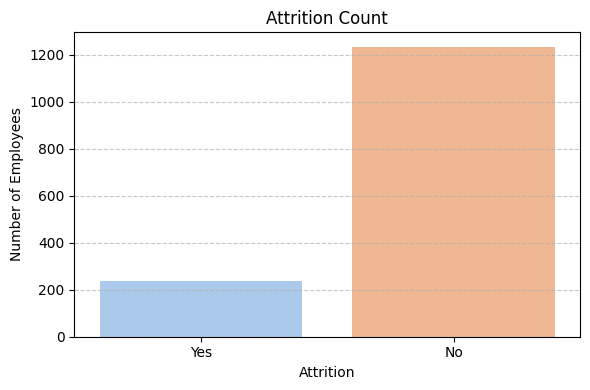

In [9]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Attrition', data=df, palette='pastel')

plt.title('Attrition Count')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

#Data Labeling

onehot encoding

In [10]:
df = pd.get_dummies(df, columns=['Department', 'EducationField', 'JobRole'])

ordinal encoding

In [11]:
from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder()
df[['Attrition','BusinessTravel','OverTime','Gender','MaritalStatus']] = encoder.fit_transform(df[['Attrition','BusinessTravel','OverTime','Gender','MaritalStatus']])

#Scaling

In [12]:
scaler = MinMaxScaler()
df = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 46 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Age                                1470 non-null   float64
 1   Attrition                          1470 non-null   float64
 2   BusinessTravel                     1470 non-null   float64
 3   DailyRate                          1470 non-null   float64
 4   DistanceFromHome                   1470 non-null   float64
 5   Education                          1470 non-null   float64
 6   EnvironmentSatisfaction            1470 non-null   float64
 7   Gender                             1470 non-null   float64
 8   HourlyRate                         1470 non-null   float64
 9   JobInvolvement                     1470 non-null   float64
 10  JobLevel                           1470 non-null   float64
 11  JobSatisfaction                    1470 non-null   float

In [14]:
col_to_move = 'Attrition'  # Replace with your actual column name
cols = [col for col in df.columns if col != col_to_move] + [col_to_move]
df = df[cols]

#Correlation Analysis

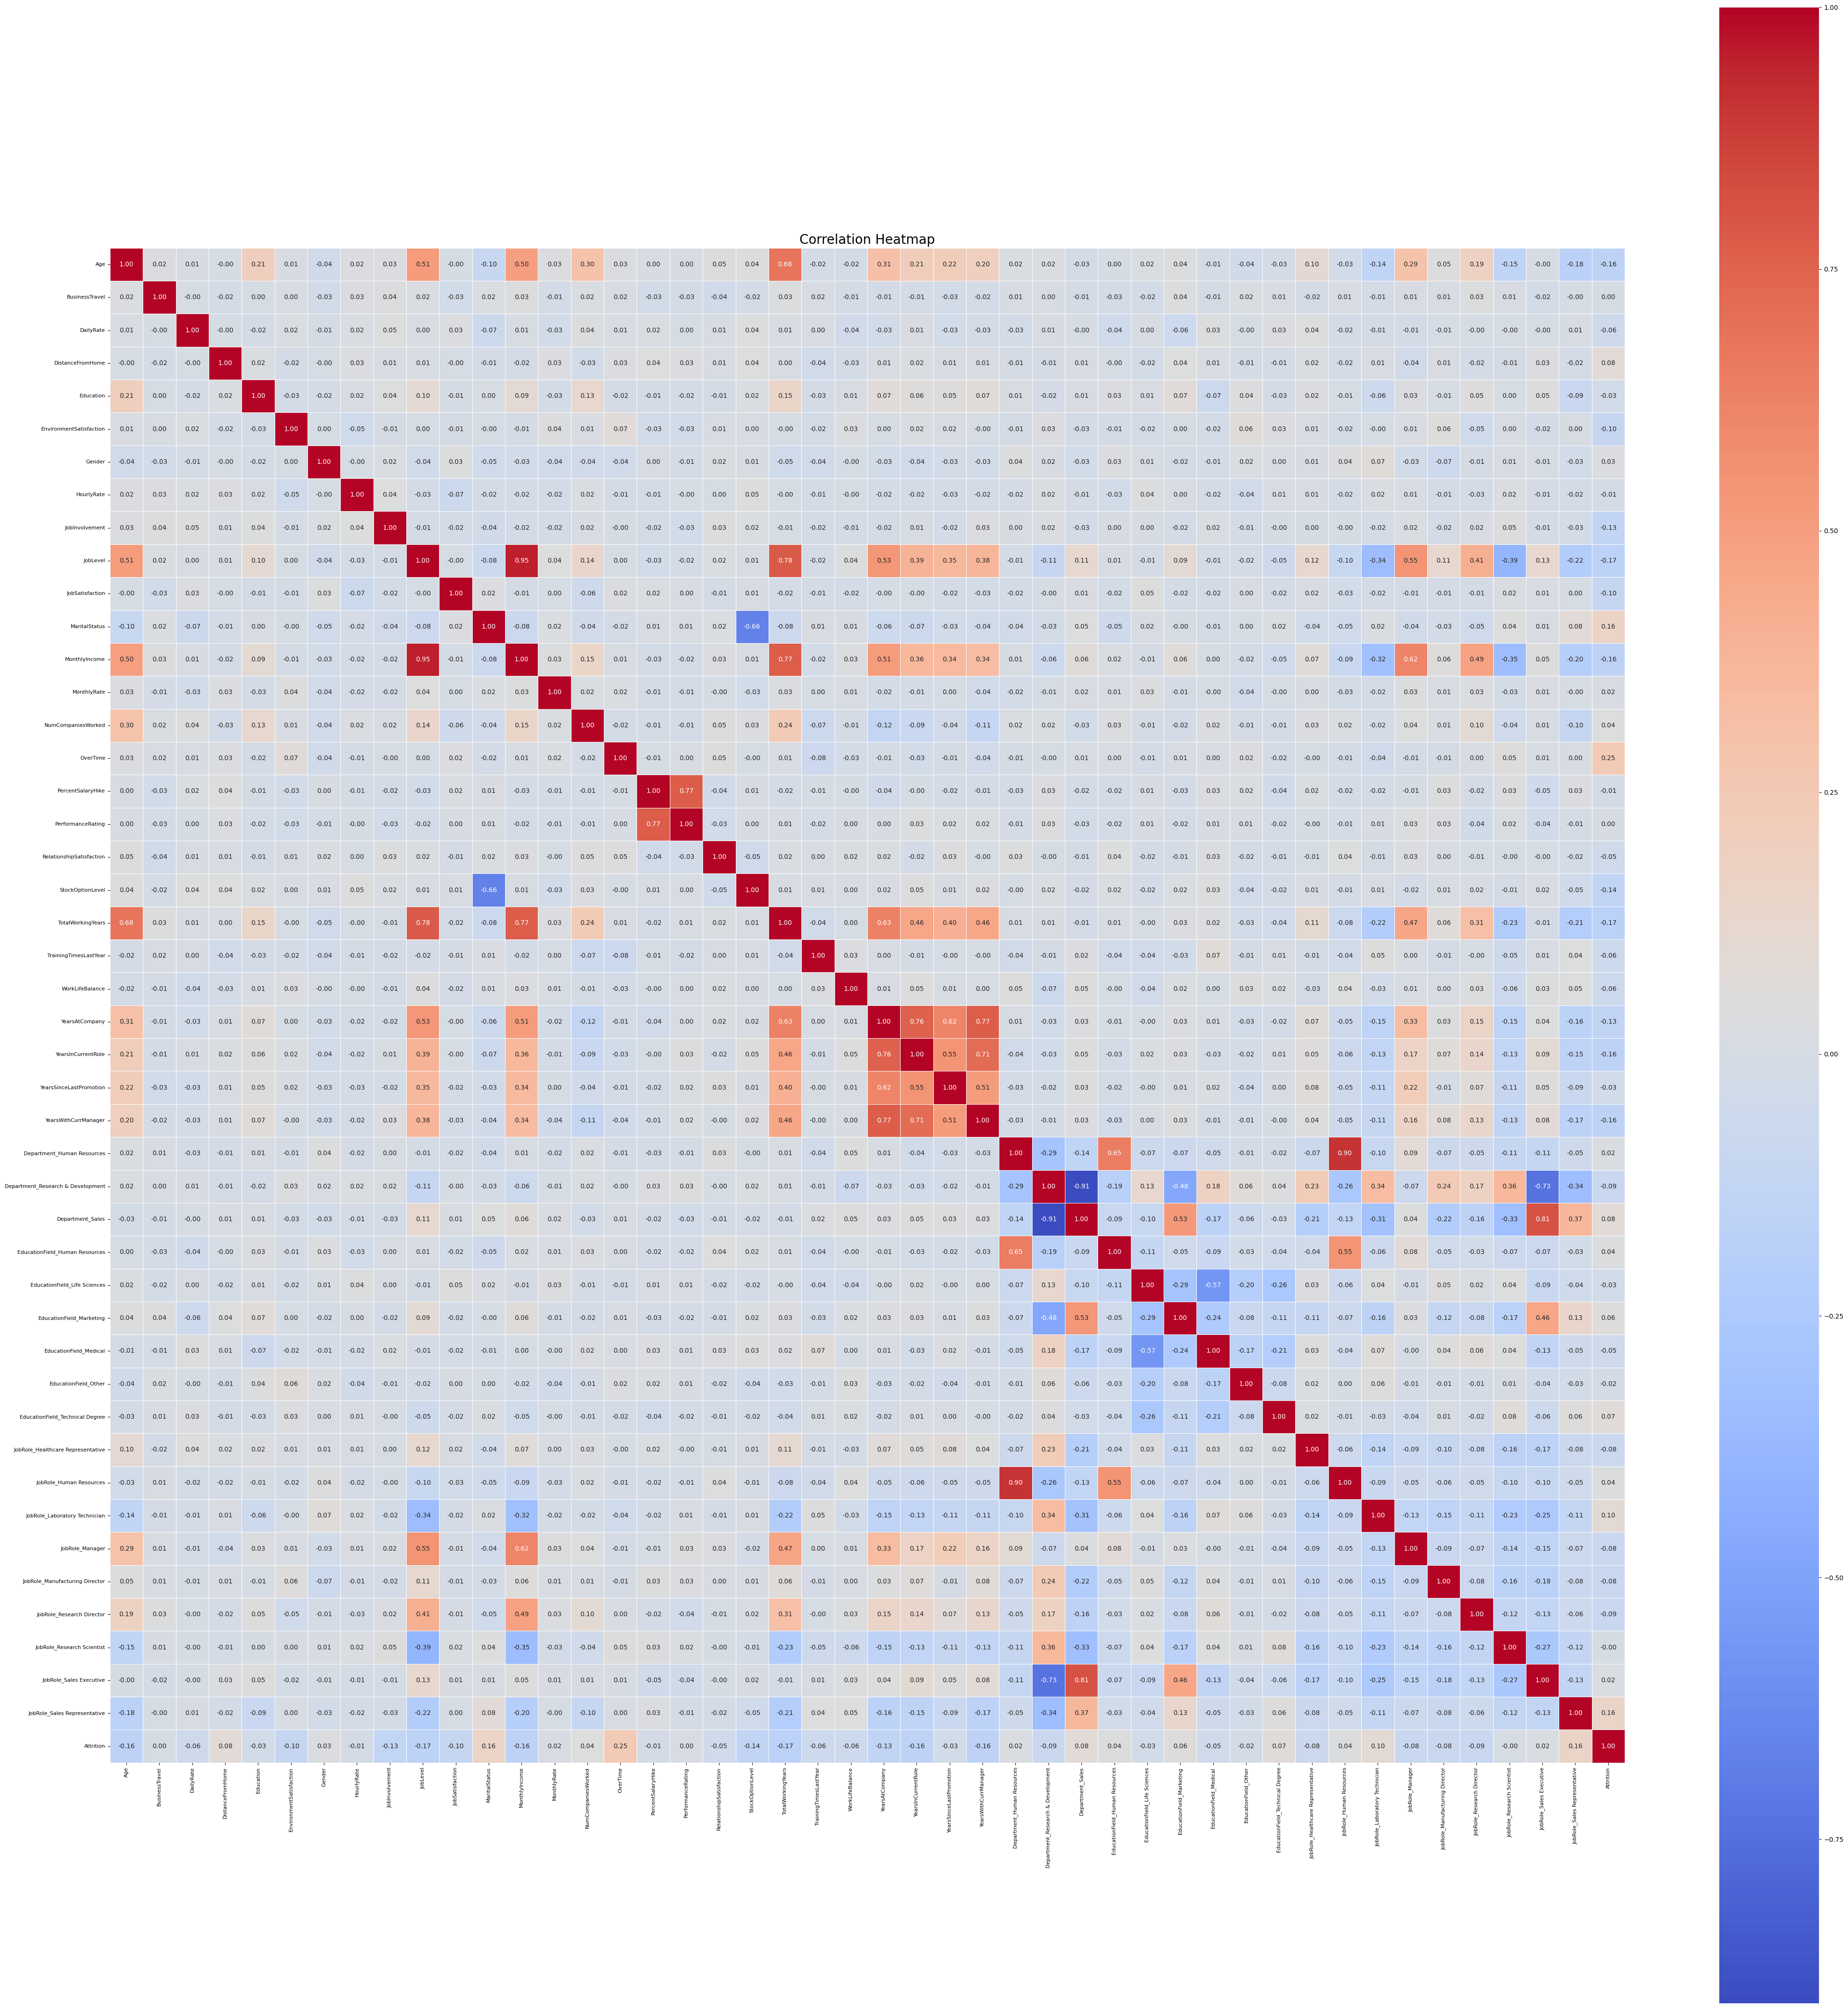

In [15]:
corr_matrix = df.corr()

# Set figure size based on number of columns (1x1 inch per feature is a good starting point)
plt.figure(figsize=(43, 43))  # You can tweak this like (30, 30) if you want slightly tighter

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, square=True)

plt.title("Correlation Heatmap", fontsize=20)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

In [16]:
correlation_series = df.corr()['Attrition'].drop('Attrition')  # Drop self-correlation
correlation_df = correlation_series.reset_index()
correlation_df.columns = ['Feature', 'CorrelationWithTarget']
correlation_df = correlation_df.sort_values(by='CorrelationWithTarget', ascending=False)

print(correlation_df)


                              Feature  CorrelationWithTarget
15                           OverTime               0.246118
11                      MaritalStatus               0.162070
44       JobRole_Sales Representative               0.157234
38      JobRole_Laboratory Technician               0.098290
29                   Department_Sales               0.080855
3                    DistanceFromHome               0.077924
35    EducationField_Technical Degree               0.069355
32           EducationField_Marketing               0.055781
14                 NumCompaniesWorked               0.043494
30     EducationField_Human Resources               0.036466
37            JobRole_Human Resources               0.036215
6                              Gender               0.029453
43            JobRole_Sales Executive               0.019774
27         Department_Human Resources               0.016832
13                        MonthlyRate               0.015170
17                  Perf

In [17]:
df['ExperienceGap'] = df['TotalWorkingYears'] - df['YearsAtCompany']
df['PromotionWaitTime'] = df['YearsAtCompany'] - df['YearsSinceLastPromotion']
df['is_sales_related'] = df['JobRole_Sales Representative'] + df['JobRole_Sales Executive']

df['MaritalStatus_OverTime'] = df['MaritalStatus'] + df['OverTime']
df['CareerDepth'] = (
    df['Age'] +
    df['MonthlyIncome'] +
    df['YearsInCurrentRole'] +
    df['JobLevel'] +
    df['TotalWorkingYears']
)


col_to_move = 'Attrition'  # Replace with your actual column name
cols = [col for col in df.columns if col != col_to_move] + [col_to_move]
df = df[cols]

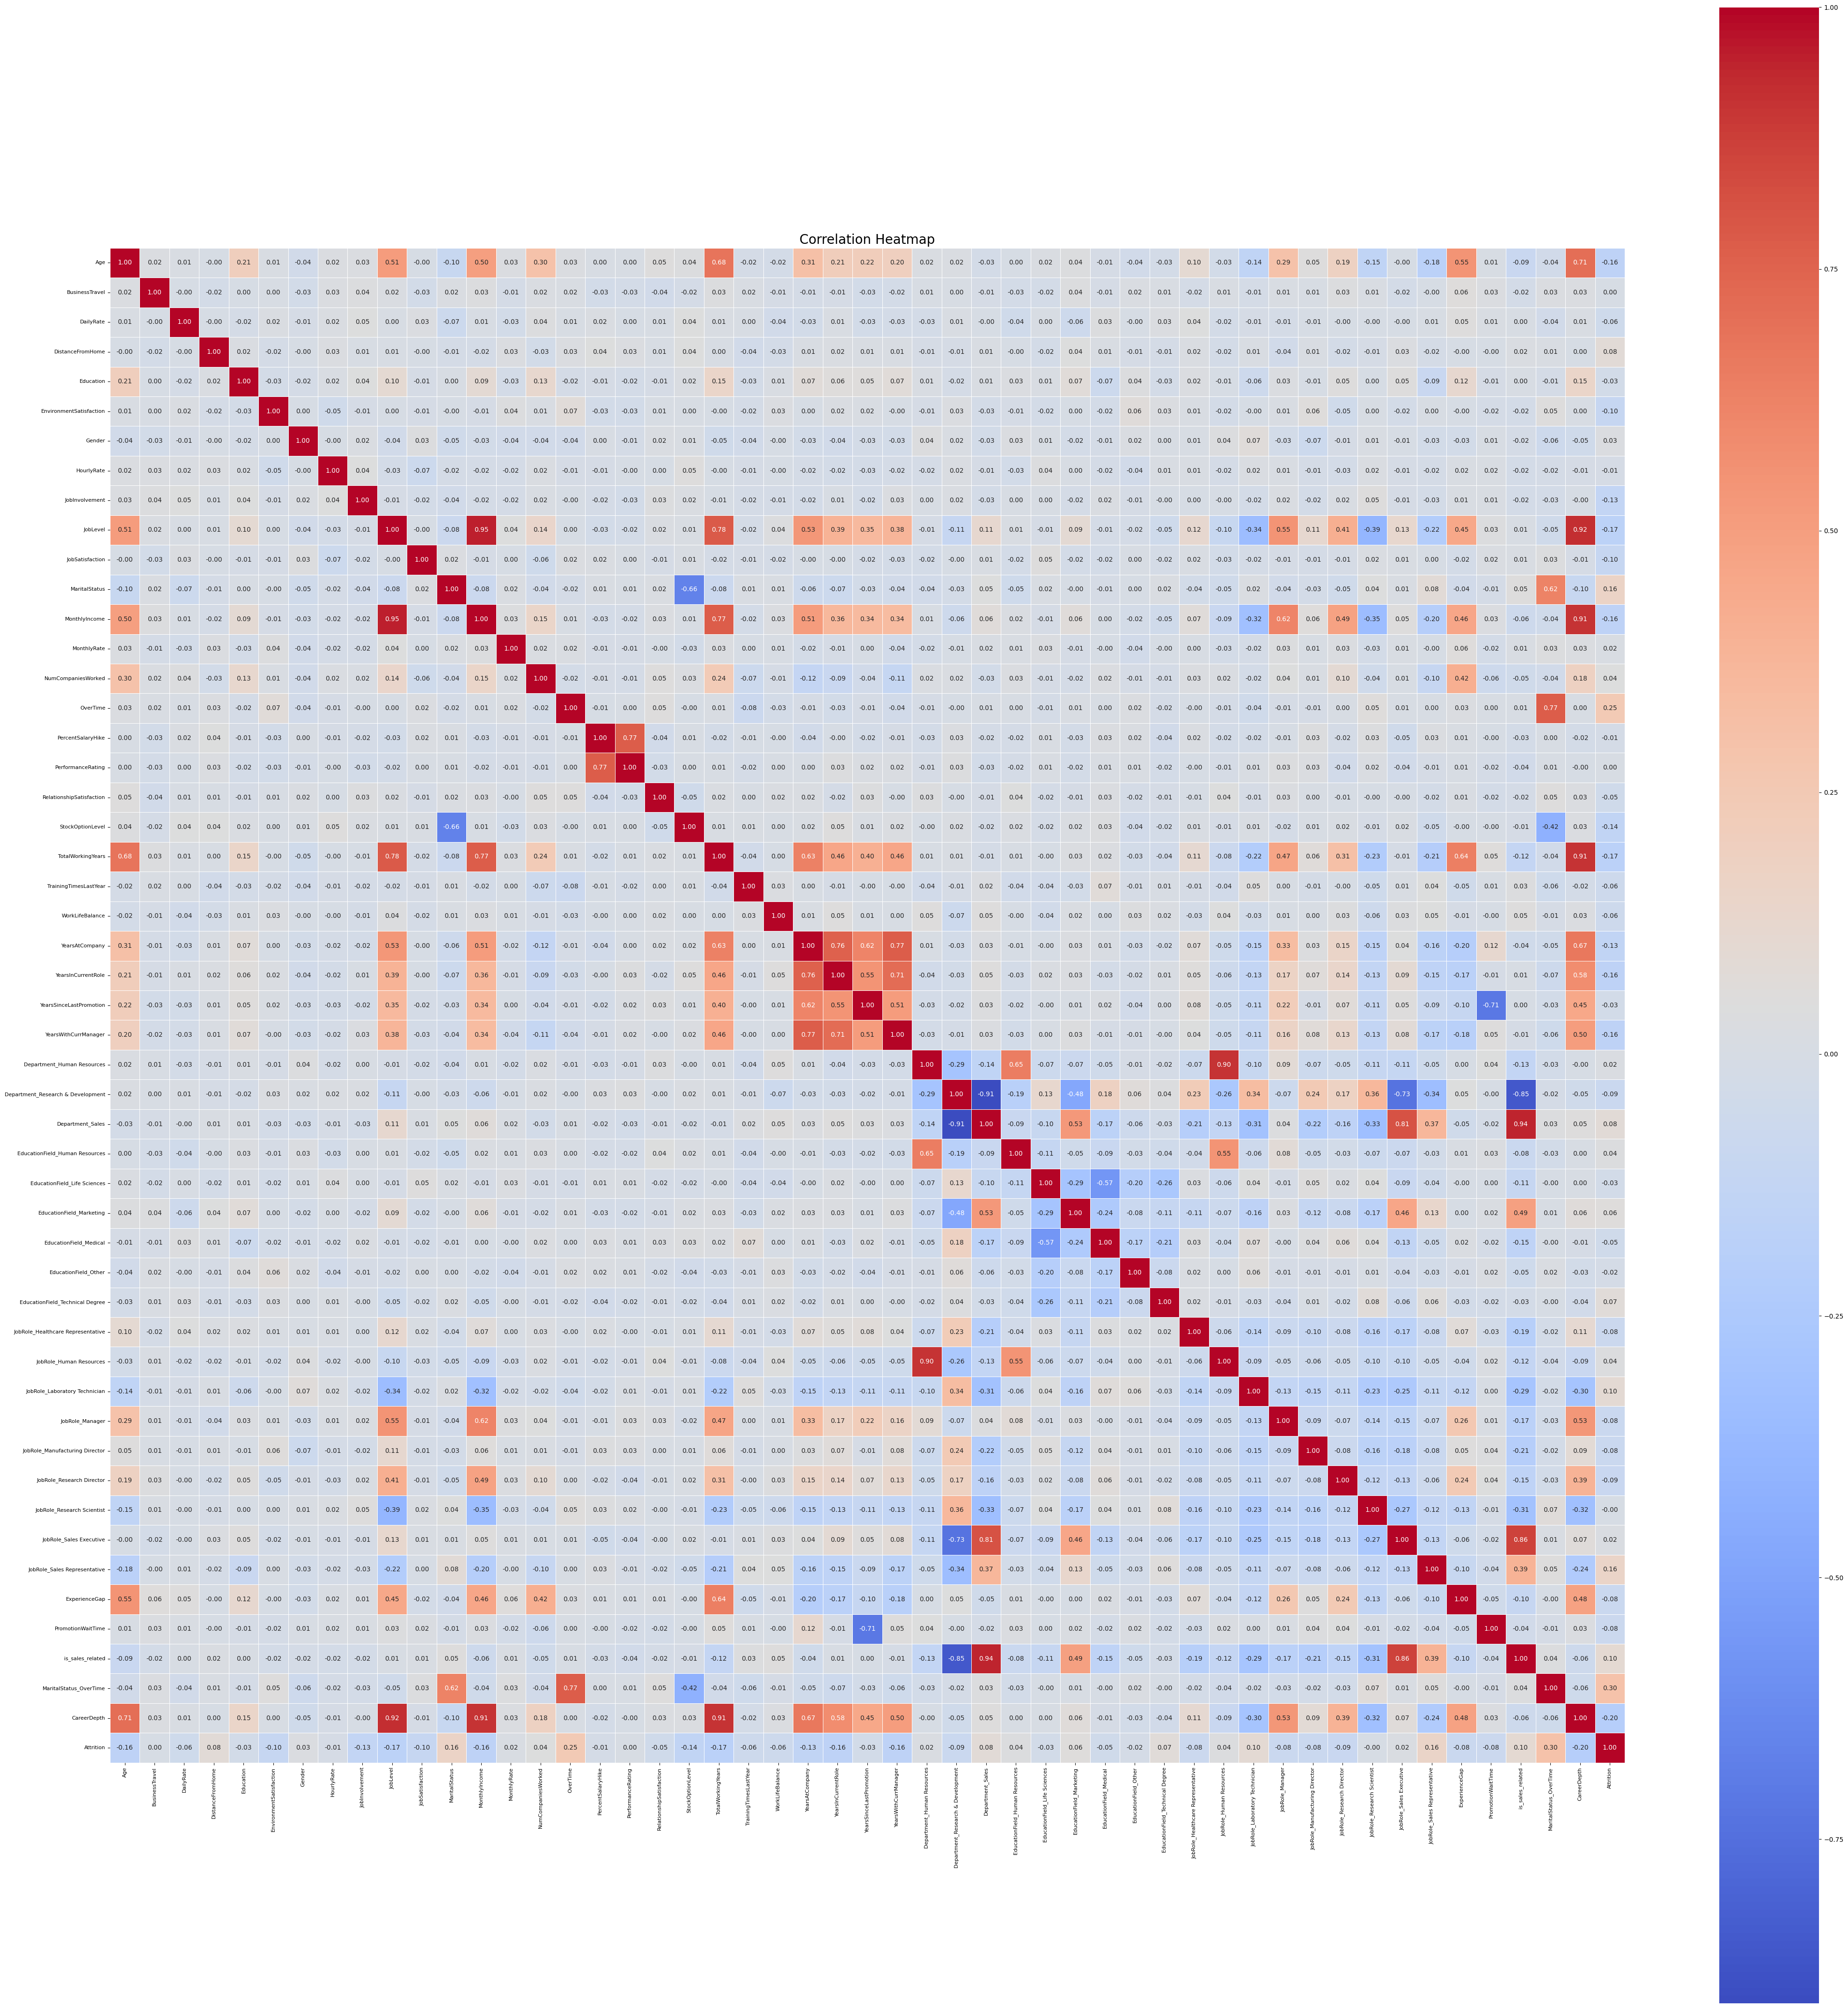

In [18]:
corr_matrix = df.corr()

# Set figure size based on number of columns (1x1 inch per feature is a good starting point)
plt.figure(figsize=(43, 43))  # You can tweak this like (30, 30) if you want slightly tighter

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, square=True)

plt.title("Correlation Heatmap", fontsize=20)
plt.xticks(rotation=90, fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

In [19]:
df_features = df.drop(columns=['Attrition'])
df_label = df['Attrition']

In [20]:
df_features.head()

,Age,BusinessTravel,DailyRate,DistanceFromHome,Education,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,...,JobRole_Manufacturing Director,JobRole_Research Director,JobRole_Research Scientist,JobRole_Sales Executive,JobRole_Sales Representative,ExperienceGap,PromotionWaitTime,is_sales_related,MaritalStatus_OverTime,CareerDepth
0,0.547619,1.0,0.715820,0.000000,0.25,0.333333,0.0,0.914286,0.666667,0.25,...,0.0,0.0,0.0,1.0,0.0,0.050,0.150000,1.0,2.0,1.482295
1,0.738095,0.5,0.126700,0.250000,0.00,0.666667,1.0,0.442857,0.333333,0.25,...,0.0,0.0,1.0,0.0,0.0,0.000,0.183333,0.0,0.5,1.843993
2,0.452381,1.0,0.909807,0.035714,0.25,1.000000,1.0,0.885714,0.333333,0.00,...,0.0,0.0,0.0,0.0,0.0,0.175,0.000000,0.0,2.0,0.684306
3,0.357143,0.5,0.923407,0.071429,0.75,1.000000,0.0,0.371429,0.666667,0.00,...,0.0,0.0,1.0,0.0,0.0,0.000,0.000000,0.0,1.5,1.046084
4,0.214286,1.0,0.350036,0.035714,0.00,0.000000,1.0,0.142857,0.666667,0.00,...,0.0,0.0,0.0,0.0,0.0,0.100,-0.083333,0.0,0.5,0.604886


In [21]:
df_label.head()

,Attrition
0,1.0
1,0.0
2,1.0
3,0.0
4,0.0


In [22]:
print("FEATURES SHAPE: ",df_features.shape)
print("LABELS SHAPE: ",df_label.shape)

FEATURES SHAPE:  (1470, 50)
LABELS SHAPE:  (1470,)


Spliting into training and test dataset

In [23]:
x_train, x_test, y_train, y_test = train_test_split(df_features, df_label, test_size=0.2, random_state=42)

In [24]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
x_train, y_train = smote.fit_resample(x_train, y_train)

#Model Building

In [25]:
def plot_confusion_matrix(cm, title="Confusion Matrix"):
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.xlabel('Predicted Labels')
    plt.ylabel('True Labels')
    plt.title(title)
    plt.show()

Decision Tree Accuracy: 0.7517006802721088
Decision Tree Classification Report:
               precision    recall  f1-score   support

         0.0       0.87      0.84      0.85       255
         1.0       0.15      0.18      0.16        39

    accuracy                           0.75       294
   macro avg       0.51      0.51      0.51       294
weighted avg       0.77      0.75      0.76       294



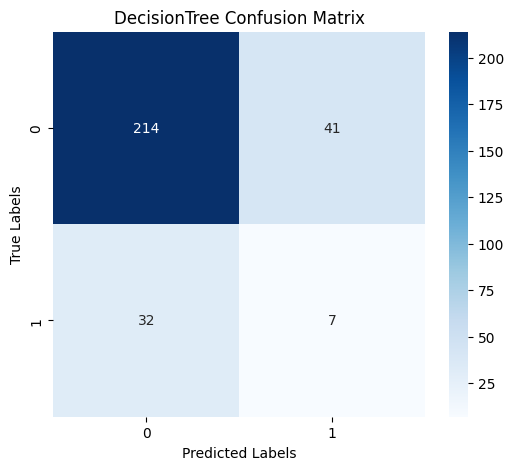

In [26]:
dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(x_train, y_train)
dt_pred = dt_model.predict(x_test)
dt_accuracy= accuracy_score(y_test, dt_pred)
print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))
print("Decision Tree Classification Report:\n", classification_report(y_test, dt_pred))
cm= confusion_matrix(y_test, dt_pred)
plot_confusion_matrix(cm, title="DecisionTree Confusion Matrix")

SVM Accuracy: 0.8095238095238095
SVM Classification Report:
               precision    recall  f1-score   support

         0.0       0.92      0.85      0.89       255
         1.0       0.35      0.51      0.42        39

    accuracy                           0.81       294
   macro avg       0.64      0.68      0.65       294
weighted avg       0.84      0.81      0.82       294



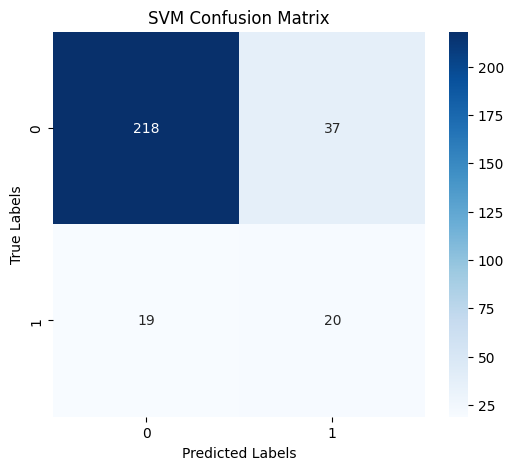

In [27]:
svm_model = SVC()
svm_model.fit(x_train, y_train)
svm_pred = svm_model.predict(x_test)
svm_accuracy= accuracy_score(y_test, svm_pred)
print("SVM Accuracy:", accuracy_score(y_test, svm_pred))
print("SVM Classification Report:\n", classification_report(y_test, svm_pred))
cm= confusion_matrix(y_test, svm_pred)
plot_confusion_matrix(cm, title="SVM Confusion Matrix")

Logistic Regression Accuracy: 0.7482993197278912
Logistic Regression Classification Report:
               precision    recall  f1-score   support

         0.0       0.93      0.77      0.84       255
         1.0       0.29      0.62      0.39        39

    accuracy                           0.75       294
   macro avg       0.61      0.69      0.62       294
weighted avg       0.84      0.75      0.78       294



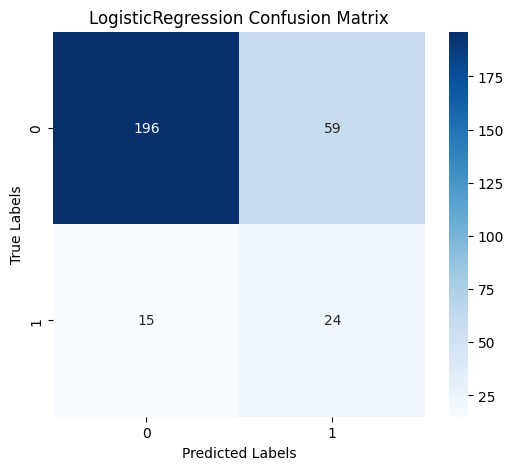

In [28]:
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(x_train, y_train)
lr_pred = lr_model.predict(x_test)
lr_accuracy= accuracy_score(y_test, lr_pred)
print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))
print("Logistic Regression Classification Report:\n", classification_report(y_test, lr_pred))
cm= confusion_matrix(y_test, lr_pred)
plot_confusion_matrix(cm, title="LogisticRegression Confusion Matrix")

KNN Accuracy: 0.6836734693877551
KNN Classification Report:
               precision    recall  f1-score   support

         0.0       0.91      0.71      0.79       255
         1.0       0.22      0.54      0.31        39

    accuracy                           0.68       294
   macro avg       0.56      0.62      0.55       294
weighted avg       0.82      0.68      0.73       294



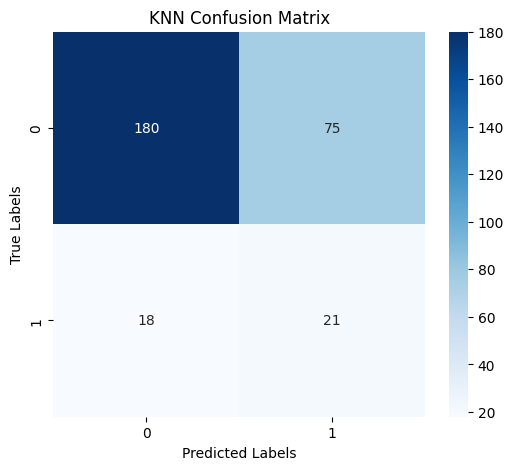

In [29]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train, y_train)
knn_pred = knn_model.predict(x_test)
knn_accuracy= accuracy_score(y_test, knn_pred)
print("KNN Accuracy:", accuracy_score(y_test, knn_pred))
print("KNN Classification Report:\n", classification_report(y_test, knn_pred))
cm= confusion_matrix(y_test, knn_pred)
plot_confusion_matrix(cm, title="KNN Confusion Matrix")


Model Comparison:
                 Model  Accuracy
1                  SVM  0.809524
0        Decision Tree  0.751701
2  Logistic Regression  0.748299
3                  KNN  0.683673


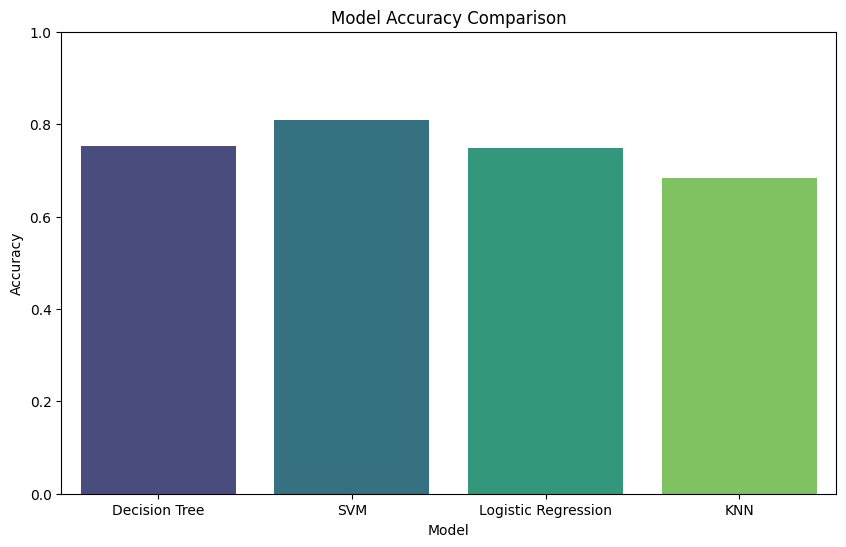

In [30]:
comparison_df = pd.DataFrame({
    'Model': ['Decision Tree', 'SVM', 'Logistic Regression', 'KNN'],
    'Accuracy': [dt_accuracy, svm_accuracy, lr_accuracy, knn_accuracy]
})

print("\nModel Comparison:")
print(comparison_df.sort_values(by='Accuracy', ascending=False))

plt.figure(figsize=(10,6))
sns.barplot(x='Model', y='Accuracy', data=comparison_df, palette='viridis')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.show()
